# Seeing the plan: cones, cuts and rewrites

The planner's decisions are invisible in code. This notebook draws them on a small
QAOA circuit (4 qubits on a path graph, 3 questions):

1. **cones**: which gates each question really needs, and what a conservative scan
   keeps anyway;
2. **cuts**: where the planner splits the circuit when states must stay small;
3. **rewrites**: what local simplification removes before planning starts.

In [1]:
import os

# One native thread per library, so timings compare algorithms rather than core counts.
# This has to happen before Qulacs is imported.
for key in ("QULACS_NUM_THREADS", "OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[key] = "1"

import matplotlib.pyplot as plt

from lazyqc import CutOptions, Program, plan_all
from lazyqc.cutting import components
from lazyqc.ir import Pauli
from lazyqc.passes import causal_cone
from lazyqc.plan import Task
from lazyqc.rewrites import local_simplify
from nbtools import cone_indices, draw_circuit, label, table

## The circuit

One QAOA layer on the path graph 0-1-2-3: a Hadamard on every qubit, a $ZZ$ phase on
each edge (CX, RZ, CX), and an RX mixer on every qubit. We ask for
$\langle Z_aZ_b\rangle$ on each edge.

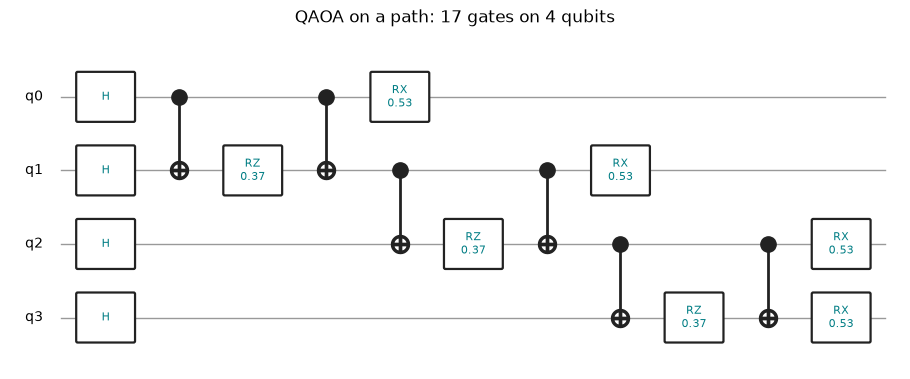

In [2]:
edges = [(0, 1), (1, 2), (2, 3)]
program = Program(4)
for q in range(4):
    program = program.h(q)
for a, b in edges:
    program = program.cx(a, b).rz(b, 0.37).cx(a, b)
for q in range(4):
    program = program.rx(q, 0.53)
requests = [program.expectation({a: "Z", b: "Z"}) for a, b in edges]
operations = program.resolved_operations()

draw_circuit(program, title=f"QAOA on a path: {len(operations)} gates on {program.n_qubits} qubits")
plt.show()

## One question, one cone

To answer $\langle Z_0Z_1\rangle$ we only need the gates that can influence qubits 0
and 1. LazyQC finds them with a backward scan: start from the observable's qubits at
the end of the circuit, walk back, and keep a gate only if it touches a qubit that is
still *active*. A kept two-qubit gate makes both of its qubits active. Every other
gate cancels exactly and is faded below.

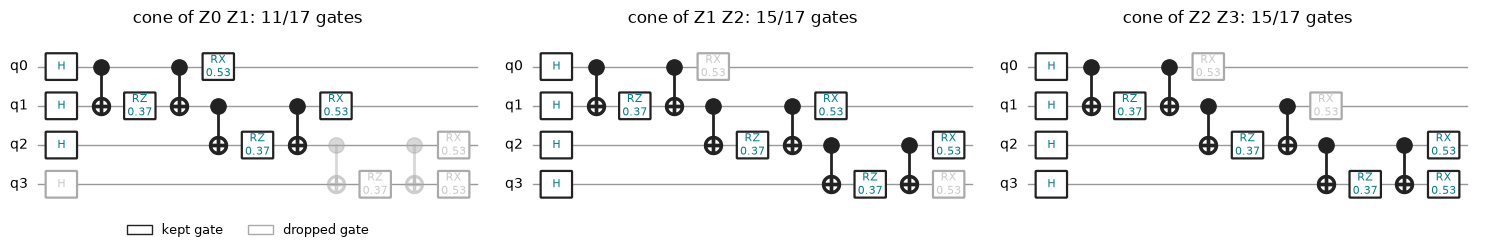

| question | gates kept | qubits simulated |
|---|---|---|
| Z0 Z1 | 11 | q0, q1, q2 |
| Z1 Z2 | 15 | q0, q1, q2, q3 |
| Z2 Z3 | 15 | q0, q1, q2, q3 |

In [3]:
fig, axes = plt.subplots(1, len(requests), figsize=(5 * len(requests), 3.8))
rows = []
for k, (ax, request) in enumerate(zip(axes, requests)):
    keep = cone_indices(operations, request.observable)
    name = label(request.observable)
    draw_circuit(program, ax=ax, keep=keep, legend=k == 0,
                 title=f"cone of {name}: {len(keep)}/{len(operations)} gates")
    wires = sorted({q for i in keep for q in operations[i].qubits})
    rows.append((name, len(keep), ", ".join(f"q{q}" for q in wires)))
fig.tight_layout()
plt.show()
table(rows, ["question", "gates kept", "qubits simulated"])

Cones can grow: a kept CX pulls its other qubit into the cone, so a two-qubit question
can need a wider simulation. They are also lopsided. The edges are applied in the
order 0-1, 1-2, 2-3, so walking back from $Z_0Z_1$ never meets the 2-3 edge, while the
cones of $Z_1Z_2$ and $Z_2Z_3$ reach back through the whole chain.

## Conservative by design

The scan keeps every gate that *touches* an active qubit, without checking whether it
can actually change the observable. That is safe but not minimal. Take $\langle Z_0\rangle$
after a CX controlled on qubit 0: a $Z$ on the control commutes with the CX, so the
gate cannot change the answer, yet the scan keeps it and pulls qubits 1 and 2 into the
cone. A commutation-aware pass such as Qiskit's `LightCone` removes it.

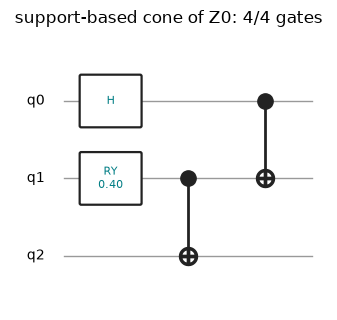

Qiskit LightCone keeps: h on q0
<Z0> = 0.0


In [4]:
from qiskit import QuantumCircuit
from qiskit.transpiler import PassManager
from qiskit.transpiler.passes import LightCone

small = Program(3).h(0).ry(1, 0.4).cx(1, 2).cx(0, 1)
z0 = small.expectation({0: "Z"})
keep = cone_indices(small.resolved_operations(), z0.observable)
draw_circuit(small, keep=keep, title=f"support-based cone of Z0: {len(keep)}/4 gates")
plt.show()

circuit = QuantumCircuit(3)
circuit.h(0)
circuit.ry(0.4, 1)
circuit.cx(1, 2)
circuit.cx(0, 1)
reduced = PassManager([LightCone(bit_terms="Z", indices=[0])]).run(circuit)
kept = [f"{i.operation.name} on q{reduced.find_bit(i.qubits[0]).index}" for i in reduced.data]
print("Qiskit LightCone keeps:", ", ".join(kept))
print("<Z0> =", plan_all([z0]).collect().values[0])

Qiskit pays for its smaller cones with an analysis per request. LazyQC trades some
cone width for a cheaper analysis keyed on circuit shape and shared across the whole
batch (notebook 03). Combining commutation-aware cones with that batch-wide reuse is
future work.

## Where the planner cuts

Now suppose no simulation may use more than 2 qubits. Every cone above is wider, so
the planner has to cut CX gates. A cut replaces the CX by a sum of local operations
on its two sides; each side becomes a separate *fragment* (a coloured band below).
The answers stay exact, at the price of more fragment simulations. Searching over the
whole batch at once (**joint** search) lets several questions share those
simulations; **independent** search plans each question on its own.

In [5]:
width = 2
memory = dict(max_state_qubits=width, max_state_bytes=16 * 2**width, total_state_bytes=32 * 2**width)
plans = {
    search: plan_all(requests, cutting=CutOptions(max_fragment_qubits=width, max_cuts=2, search=search), **memory)
    for search in ("independent", "joint")
}
table(
    [(search, len(plan.selected.tasks), len(plan.selected.groups)) for search, plan in plans.items()],
    ["cut search", "fragment experiments", "groups"],
)

| cut search | fragment experiments | groups |
|---|---|---|
| independent | 148 | 3 |
| joint | 67 | 1 |

Each group of the joint plan simulates one cone, split at its cut CX gates. Here is
what each group looks like:

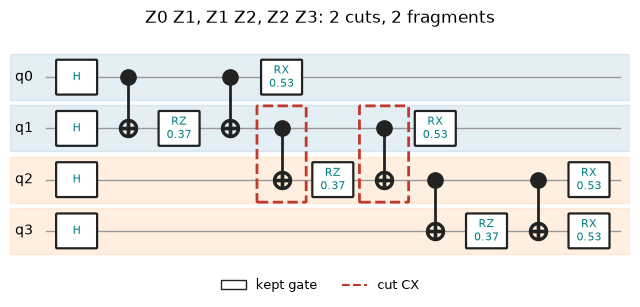

| questions | cuts | fragments (qubits) |
|---|---|---|
| Z0 Z1, Z1 Z2, Z2 Z3 | 2 | q0, q1 | q2, q3 |

In [6]:
def group_view(group):
    """Questions served by a group, the cone it simulates and its fragment wires."""
    outputs = sorted({formula.output for formula in group.formulas})
    support = sorted({q for o in outputs for q, _ in requests[o].observable.factors})
    wires, cone = causal_cone(operations, Pauli(tuple((q, "Z") for q in support)))
    task = Task(tuple(wires), tuple(cone), tuple((o, requests[o].observable) for o in outputs))
    parts = components(task, tuple(group.cut_indices))
    fragments = {q: i for i, part in enumerate(parts) for q in part}
    return outputs, Program(program.n_qubits, tuple(cone)), fragments, parts


groups = list(plans["joint"].selected.groups)
fig, axes = plt.subplots(1, len(groups), figsize=(6.5 * len(groups), 4.2), squeeze=False)
rows = []
for ax, group in zip(axes[0], groups):
    outputs, cone_program, fragments, parts = group_view(group)
    names = ", ".join(label(requests[o].observable) for o in outputs)
    draw_circuit(cone_program, ax=ax, cuts=set(group.cut_indices), fragments=fragments, legend=True,
                 title=f"{names}: {len(group.cut_indices)} cuts, {len(parts)} fragments")
    rows.append((names, len(group.cut_indices), " | ".join(", ".join(f"q{q}" for q in sorted(p)) for p in parts)))
fig.tight_layout()
plt.show()
table(rows, ["questions", "cuts", "fragments (qubits)"])

## What rewriting removes

LazyQC can simplify a circuit before planning. `local_simplify` only applies exact
rules: adjacent inverse pairs cancel and zero-angle rotations vanish. It never merges
rotations approximately. The crafted circuit below shows each rule: the two $H$ gates
cancel, $RZ(0)$ disappears and $RY(0.3)$ followed by $RY(-0.3)$ cancels, while
$RY(0.3)$ followed by $RY(0.2)$ stays as two gates.

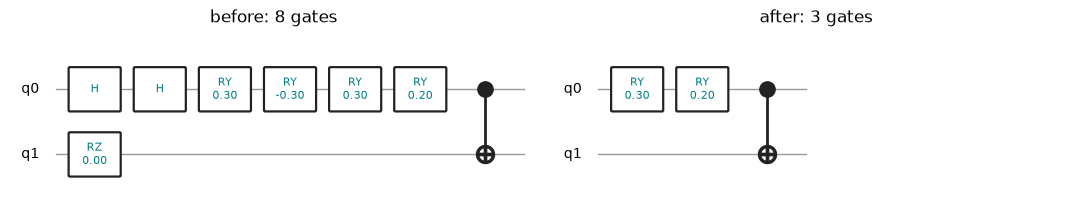

In [7]:
messy = Program(2).h(0).h(0).rz(1, 0.0).ry(0, 0.3).ry(0, -0.3).ry(0, 0.3).ry(0, 0.2).cx(0, 1)
before = messy.resolved_operations()
after = local_simplify(before)

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.2))
draw_circuit(messy, ax=left, title=f"before: {len(before)} gates")
draw_circuit(Program(2, tuple(after)), ax=right, title=f"after: {len(after)} gates")
right.set_xlim(left.get_xlim())  # same scale on both sides
fig.tight_layout()
plt.show()

## What the pictures teach

- Cones prune before anything is simulated. The analysis is conservative: it keeps
  any gate that touches an active qubit, even one that would commute away, where
  Qiskit's `LightCone` would drop it.
- Cuts trade width for count: smaller states, more fragment simulations. Joint search
  shares those simulations across questions (compare the two counts above).
- Rewrites change the circuit before cones are computed, so any reuse of planning
  decisions has to be keyed on the rewritten circuit (notebook 04, scenario 3).
- Nothing here samples: every value is exact up to floating-point rounding.

## Try it yourself

- Raise `width` to 3 and see how many cuts remain.
- Ask a question about distant qubits, such as `{0: "Z", 3: "Z"}`, and draw its cone.